# 03 · Cohort retention

**Goal:** measure how well the business keeps the customers it acquires.
- How does retention decay as customers age?
- Do customers acquired in the autumn peak come back as often as the others?
- How long can a customer stay silent and still come back? This feeds the churn definition in `04`.

**Input:** `transactions` from `01` (product purchases, cancelled orders removed). This notebook is descriptive and has no cutoff date, so using cancellations from the whole period is fine here. It would not be in `04`.

In [1]:
import sys
from datetime import date
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import polars as pl
from statsmodels.duration.survfunc import SurvfuncRight, survdiff

from src.config import RANDOM_STATE, TRANSACTIONS
from src.plotting import INK, INK_SECONDARY, NEUTRAL, SEQUENTIAL_CMAP, save_fig, set_style
from src.retention import cohort_activity, purchase_intervals, retention_table

set_style()
pl.Config.set_tbl_cols(-1)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_rows(25)
transactions = pl.read_parquet(TRANSACTIONS)

DATA_END = transactions["invoice_date"].max().date()
LAST_FULL_MONTH = date(2011, 11, 1)  # December 2011 stops on the 9th
FIRST_NEW_COHORT = date(2010, 1, 1)  # December 2009 holds customers acquired before the data starts
CLEAN_NEW_COHORT = date(2010, 4, 1)  # first three months of 2010 still contain earlier customers (section 1)
PEAK_MONTHS = [9, 10, 11]  # the autumn sales peak found in 01
print(f"Data ends {DATA_END}")


def km_at(sf: SurvfuncRight, days: int) -> tuple[float, float]:
    """Share that has had the event by `days` (1 - survival) and its Greenwood standard error."""
    i = np.searchsorted(sf.surv_times, days, side="right") - 1
    return (0.0, 0.0) if i < 0 else (1 - sf.surv_prob[i], sf.surv_prob_se[i])


def survival_at(sf: SurvfuncRight, x: np.ndarray) -> np.ndarray:
    i = np.searchsorted(sf.surv_times, x, side="right") - 1
    return np.where(i < 0, 1.0, sf.surv_prob[np.clip(i, 0, None)])


def conditional_return(sf: SurvfuncRight, silent_days: np.ndarray, window: int) -> np.ndarray:
    # Chance that a silence ends within `window` more days, given it has lasted `silent_days`
    s_now, s_later = survival_at(sf, silent_days), survival_at(sf, silent_days + window)
    return (s_now - s_later) / s_now


# Time from each new customer's first purchase day to their second one (censored if not seen yet)
first_intervals = purchase_intervals(transactions, DATA_END).filter(
    pl.col("interval_number") == 1, pl.col("start") >= FIRST_NEW_COHORT
)

Data ends 2011-12-09


## 1. Cohorts

- A customer's **cohort** is the month of their first purchase in the data.
- A customer is **active** in a month if they bought at least once in it.
- **Retention at month k** is the share of the cohort that is active k months after the acquisition month.

There are three caveats:
- **The December 2009 cohort is not new customers.** The data starts that month, so it includes the existing customer base. It is shown separately as a benchmark.
- **The early-2010 cohorts are not entirely new either.** Customers who last bought before December 2009 look "new" when they come back. The check below shows how much this matters.
- **Recent cohorts have been observed for fewer months** (right-censoring). Unobserved cells stay empty and are never counted as zero.

In [2]:
activity = cohort_activity(transactions, LAST_FULL_MONTH)
retention = retention_table(activity)

sizes = retention.filter(pl.col("months_since_first") == 0).select("cohort", "cohort_size")
print(f"Existing customers (Dec 2009 cohort): {sizes.filter(pl.col('cohort') < FIRST_NEW_COHORT)['cohort_size'].sum():,}")
print(f"New customers, Jan 2010 - Nov 2011: {sizes.filter(pl.col('cohort') >= FIRST_NEW_COHORT)['cohort_size'].sum():,} "
      f"in {sizes.filter(pl.col('cohort') >= FIRST_NEW_COHORT).height} monthly cohorts")
print(sizes.with_columns(pl.col("cohort").dt.strftime("%b %Y")).transpose(include_header=False, column_names="cohort"))

Existing customers (Dec 2009 cohort): 951
New customers, Jan 2010 - Nov 2011: 4,861 in 23 monthly cohorts
shape: (1, 24)
┌────────┬────────┬────────┬────────┬────────┬────────┬────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┐
│ Dec    ┆ Jan    ┆ Feb    ┆ Mar    ┆ Apr    ┆ May    ┆ Jun    ┆ Jul   ┆ Aug   ┆ Sep   ┆ Oct   ┆ Nov   ┆ Dec   ┆ Jan   ┆ Feb   ┆ Mar   ┆ Apr   ┆ May   ┆ Jun   ┆ Jul   ┆ Aug   ┆ Sep   ┆ Oct   ┆ Nov   │
│ 2009   ┆ 2010   ┆ 2010   ┆ 2010   ┆ 2010   ┆ 2010   ┆ 2010   ┆ 2010  ┆ 2010  ┆ 2010  ┆ 2010  ┆ 2010  ┆ 2010  ┆ 2011  ┆ 2011  ┆ 2011  ┆ 2011  ┆ 2011  ┆ 2011  ┆ 2011  ┆ 2011  ┆ 2011  ┆ 2011  ┆ 2011  │
│ ---    ┆ ---    ┆ ---    ┆ ---    ┆ ---    ┆ ---    ┆ ---    ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   ┆ ---   │
│ u32    ┆ u32    ┆ u32    ┆ u32    ┆ u32    ┆ u32    ┆ u32    ┆ u32   ┆ u3

In [3]:
# Are the early-2010 "new" customers really new? Compare their return rate with the following months of 2010.
# Kaplan-Meier handles customers who have not had a full year to come back yet.
early_check = []
for label, start, end in [("Jan-Mar 2010", date(2010, 1, 1), date(2010, 3, 31)),
                          ("Apr-Aug 2010", date(2010, 4, 1), date(2010, 8, 31))]:
    part = first_intervals.filter(pl.col("start").is_between(start, end))
    p, se = km_at(SurvfuncRight(part["duration"].to_numpy(), part["event"].to_numpy()), 365)
    early_check.append({"acquired": label, "customers": part.height, "second_order_within_365d_pct": round(p * 100, 1),
                        "ci_low": round((p - 1.96 * se) * 100, 1), "ci_high": round((p + 1.96 * se) * 100, 1)})
pl.DataFrame(early_check)

acquired,customers,second_order_within_365d_pct,ci_low,ci_high
str,i64,f64,f64,f64
"""Jan-Mar 2010""",1181,80.3,78.0,82.5
"""Apr-Aug 2010""",1162,69.7,67.1,72.3


Customers "acquired" in January–March 2010 come back much more often than those acquired a few months later. This is what returning customers from before the data would look like. **From here on, comparisons of new customers use cohorts from April 2010.** The January–March 2010 cohorts stay in the heatmap, marked with an asterisk.

## 2. How does each cohort's retention evolve?

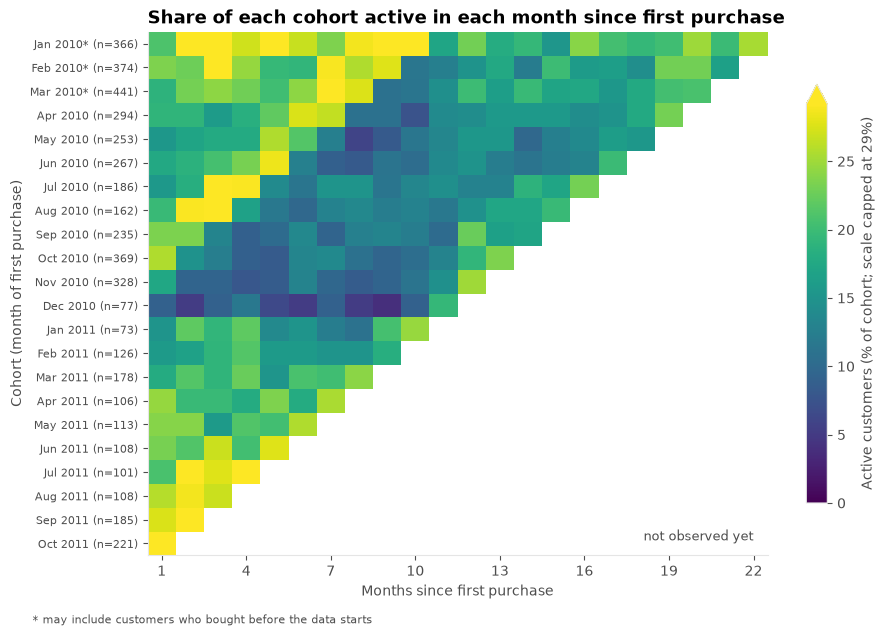

In [4]:
MAX_K = 22
heat = (
    retention.filter(pl.col("cohort") >= FIRST_NEW_COHORT, pl.col("months_since_first").is_between(1, MAX_K))
    .pivot(on="months_since_first", index="cohort", values="retention", sort_columns=True)
    .sort("cohort")
)
size_of = dict(sizes.iter_rows())
cohort_labels = [f"{c:%b %Y}{'*' if c < CLEAN_NEW_COHORT else ''} (n={size_of[c]})" for c in heat["cohort"]]
matrix = heat.drop("cohort").to_numpy().astype(float) * 100

# Month 0 is always 100%, so it is left out; the colour scale is capped at the 95th percentile
vmax = np.nanpercentile(matrix, 95)
fig, ax = plt.subplots(figsize=(10, 6.8))
image = ax.imshow(np.ma.masked_invalid(matrix), cmap=SEQUENTIAL_CMAP, vmin=0, vmax=vmax, aspect="auto")
ax.set_xticks(range(0, MAX_K, 3), [str(k) for k in range(1, MAX_K + 1, 3)])
ax.set_yticks(range(len(cohort_labels)), cohort_labels, fontsize=8)
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Cohort (month of first purchase)")
ax.set_title("Share of each cohort active in each month since first purchase")
ax.grid(False)
colorbar = fig.colorbar(image, ax=ax, extend="max", shrink=0.8)
colorbar.set_label(f"Active customers (% of cohort; scale capped at {vmax:.0f}%)")
ax.text(MAX_K - 1, len(cohort_labels) - 1, "not observed yet", ha="right", va="bottom", color=INK_SECONDARY, fontsize=9)
fig.text(0.01, 0.01, "* may include customers who bought before the data starts", color=INK_SECONDARY, fontsize=8)
save_fig(fig, "03_cohort_heatmap")
plt.show()

In [5]:
# The diagonal bands: is activity driven by the calendar month rather than by customer age?
by_calendar = (
    activity.filter(pl.col("cohort") >= CLEAN_NEW_COHORT, pl.col("months_since_first") >= 1)
    .group_by(calendar_month=pl.col("month").dt.month())
    .agg(active=pl.len())
    .join(
        activity.filter(pl.col("cohort") >= CLEAN_NEW_COHORT)
        .select("customer_id", "cohort").unique()
        .join(activity.select("month").unique(), how="cross")
        .filter(pl.col("month") > pl.col("cohort"))
        .group_by(calendar_month=pl.col("month").dt.month()).agg(already_acquired=pl.len()),
        on="calendar_month",
    )
    .with_columns(pct_active=(pl.col("active") / pl.col("already_acquired") * 100).round(1))
    .sort("calendar_month")
    .with_columns(month=pl.date(2000, pl.col("calendar_month"), 1).dt.strftime("%b"))
)
print("Share of already-acquired new customers (clean cohorts) who buy in each calendar month (%):")
print(by_calendar.select("month", "pct_active").transpose(include_header=False, column_names="month"))

Share of already-acquired new customers (clean cohorts) who buy in each calendar month (%):
shape: (1, 12)
┌─────┬─────┬──────┬──────┬──────┬──────┬──────┬──────┬──────┬──────┬──────┬──────┐
│ Jan ┆ Feb ┆ Mar  ┆ Apr  ┆ May  ┆ Jun  ┆ Jul  ┆ Aug  ┆ Sep  ┆ Oct  ┆ Nov  ┆ Dec  │
│ --- ┆ --- ┆ ---  ┆ ---  ┆ ---  ┆ ---  ┆ ---  ┆ ---  ┆ ---  ┆ ---  ┆ ---  ┆ ---  │
│ f64 ┆ f64 ┆ f64  ┆ f64  ┆ f64  ┆ f64  ┆ f64  ┆ f64  ┆ f64  ┆ f64  ┆ f64  ┆ f64  │
╞═════╪═════╪══════╪══════╪══════╪══════╪══════╪══════╪══════╪══════╪══════╪══════╡
│ 9.9 ┆ 9.4 ┆ 11.9 ┆ 12.6 ┆ 15.5 ┆ 14.9 ┆ 14.3 ┆ 14.2 ┆ 17.6 ┆ 20.6 ┆ 24.7 ┆ 14.0 │
└─────┴─────┴──────┴──────┴──────┴──────┴──────┴──────┴──────┴──────┴──────┴──────┘


**Findings: cohort heatmap**

- **The bright cells line up on diagonals,** that is, on the same calendar months. For clean cohorts, the share of already-acquired customers who buy in a month goes from about one in ten in January to one in four in November. The calendar shapes retention as much as customer age does.
- The December 2010 cohort retains worst, but it is small (77 customers). The January–March 2010 cohorts are flagged as partly pre-existing customers (section 1).

## 3. How fast does retention decay?

Averaging the heatmap columns directly would mix cohorts: later months would only contain the oldest cohorts. The curve therefore uses a balanced panel: every clean new cohort observed for at least 12 months (April to November 2010), weighted by cohort size. The December 2009 customers are shown alongside as a benchmark.

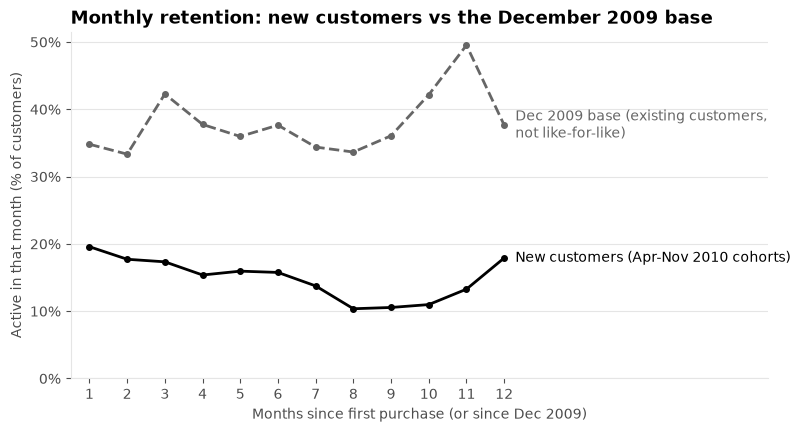

months_since_first,retention,retention_dec_2009
i32,f64,f64
1,19.6,34.8
2,17.7,33.3
3,17.3,42.3
4,15.4,37.7
5,16.0,36.0
6,15.8,37.6
7,13.8,34.4
8,10.4,33.6
9,10.6,36.1


In [6]:
HORIZON = 12
balanced = retention.filter(
    pl.col("cohort").is_between(CLEAN_NEW_COHORT, date(2010, 11, 1)), pl.col("months_since_first").is_between(1, HORIZON)
)
assert balanced.group_by("cohort").len()["len"].min() == HORIZON  # every cohort observed for all 12 months

curve_new = balanced.group_by("months_since_first").agg(
    retention=pl.col("active").sum() / pl.col("cohort_size").sum() * 100
).sort("months_since_first")
curve_existing = retention.filter(
    pl.col("cohort") < FIRST_NEW_COHORT, pl.col("months_since_first").is_between(1, HORIZON)
).select("months_since_first", retention=pl.col("retention") * 100)

fig, ax = plt.subplots(figsize=(9, 4.5))
for curve, label, style in [(curve_existing, "Dec 2009 base (existing customers,\nnot like-for-like)", "--"),
                            (curve_new, "New customers (Apr-Nov 2010 cohorts)", "-")]:
    color = NEUTRAL if style == "--" else INK
    ax.plot(curve["months_since_first"], curve["retention"], style, marker="o", markersize=4, color=color)
    ax.annotate(label, (HORIZON, curve["retention"][-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=color)
ax.set_xlim(0.5, HORIZON + 7)
ax.set_xticks(range(1, HORIZON + 1))
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Months since first purchase (or since Dec 2009)")
ax.set_ylabel("Active in that month (% of customers)")
ax.set_title("Monthly retention: new customers vs the December 2009 base")
save_fig(fig, "03_retention_curve")
plt.show()

curve_new.join(curve_existing, on="months_since_first", suffix="_dec_2009").with_columns(
    pl.exclude("months_since_first").round(1)
)

**Findings: retention curve**

- **In their first year, between about one in ten and one in five new customers are active in any given month.** Activity is highest just after acquisition and lowest around months 8–10. This is partly the calendar: for the autumn cohorts, those months fall in late spring and summer. The rise at month 12 comes mostly from the autumn cohorts reaching the next autumn.
- **The December 2009 base is about two to four times as active.** This is not a like-for-like comparison: that "cohort" is everyone who bought in one peak month, so it over-represents frequent buyers. It is a benchmark, not evidence that older customers are better.

## 4. Do customers acquired in the autumn peak come back?

The question is how long a new customer takes to place a **second order** (on a different day), and whether that depends on when they were acquired. Recent customers have had little time to come back, and counting them as "did not return" would bias the result. So the time to the second order is estimated with **Kaplan-Meier**, which treats them as censored. The confidence intervals are pointwise, 95%, from Greenwood standard errors.

- **Groups:** first purchase in September–November (the autumn peak) against the other months, for clean new customers (acquired from April 2010).
- **Main horizon:** 365 days, fixed in advance. By then both groups have gone through a full seasonal cycle.
- **Sensitivity check:** the main comparison mixes 2010 and 2011 acquisitions. A year-matched check uses 2010 only: April–August against September–November.

In [7]:
GROUPS = {True: "Acquired Sep-Nov (peak)", False: "Acquired in other months"}
HORIZONS = [30, 90, 180, 365]
new_customers = first_intervals.filter(pl.col("start") >= CLEAN_NEW_COHORT).with_columns(
    acquired_in_peak=pl.col("start").dt.month().is_in(PEAK_MONTHS)
)


def fit_groups(df: pl.DataFrame) -> dict[bool, SurvfuncRight]:
    return {peak: SurvfuncRight(part["duration"].to_numpy(), part["event"].to_numpy())
            for peak in (True, False) for part in [df.filter(pl.col("acquired_in_peak") == peak)]}


def horizon_table(fits: dict[bool, SurvfuncRight], horizons: list[int]) -> pl.DataFrame:
    rows = []
    for h in horizons:
        (p_peak, se_peak), (p_other, se_other) = km_at(fits[True], h), km_at(fits[False], h)
        diff, margin = (p_other - p_peak) * 100, 1.96 * np.hypot(se_peak, se_other) * 100
        rows.append({"days": h, "peak_pct": p_peak * 100, "other_pct": p_other * 100,
                     "other_minus_peak": diff, "ci_low": diff - margin, "ci_high": diff + margin})
    return pl.DataFrame(rows).with_columns(pl.exclude("days").round(1))


fits = fit_groups(new_customers)
print(new_customers.group_by("acquired_in_peak").agg(customers=pl.len()).sort("acquired_in_peak"))
horizon_table(fits, HORIZONS)

shape: (2, 2)
┌──────────────────┬───────────┐
│ acquired_in_peak ┆ customers │
│ ---              ┆ ---       │
│ bool             ┆ u32       │
╞══════════════════╪═══════════╡
│ false            ┆ 2178      │
│ true             ┆ 1528      │
└──────────────────┴───────────┘


days,peak_pct,other_pct,other_minus_peak,ci_low,ci_high
i64,f64,f64,f64,f64,f64
30,21.6,15.5,-6.1,-8.7,-3.5
90,41.7,39.0,-2.7,-6.0,0.7
180,49.4,57.6,8.2,4.7,11.7
365,61.2,69.0,7.8,4.3,11.3


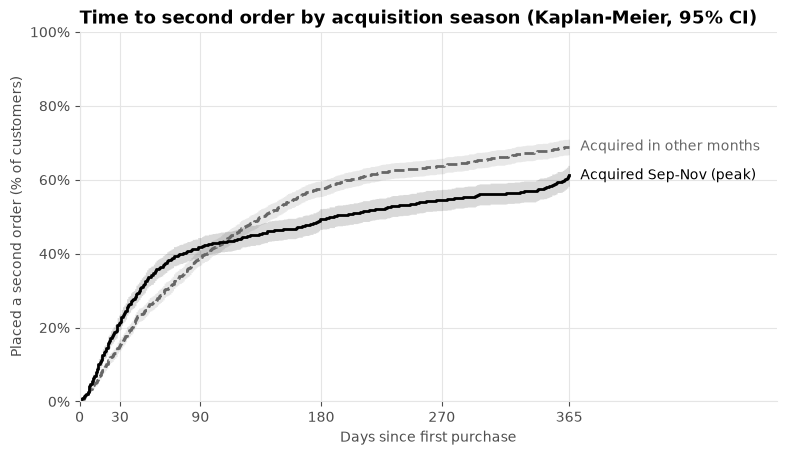

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.8))
grid = np.arange(0, 366)
for peak, style in [(False, "--"), (True, "-")]:
    returned = np.array([km_at(fits[peak], d) for d in grid])
    color = INK if peak else NEUTRAL
    ax.step(grid, returned[:, 0] * 100, where="post", linestyle=style, color=color)
    ax.fill_between(grid, (returned[:, 0] - 1.96 * returned[:, 1]) * 100, (returned[:, 0] + 1.96 * returned[:, 1]) * 100,
                    step="post", color=color, alpha=0.15, linewidth=0)
    ax.annotate(GROUPS[peak], (365, returned[-1, 0] * 100), xytext=(8, 0), textcoords="offset points",
                va="center", color=color)
ax.set_xlim(0, 520)
ax.set_xticks([0, 30, 90, 180, 270, 365])
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Days since first purchase")
ax.set_ylabel("Placed a second order (% of customers)")
ax.set_title("Time to second order by acquisition season (Kaplan-Meier, 95% CI)")
ax.grid(axis="x")
save_fig(fig, "03_second_order_by_season")
plt.show()

In [9]:
# Sensitivity: 2010 acquisitions only, so both groups come from the same year
same_year = new_customers.filter(pl.col("start") < date(2010, 12, 1))
print(same_year.group_by("acquired_in_peak").agg(customers=pl.len()).sort("acquired_in_peak"))
horizon_table(fit_groups(same_year), [30, 365])

shape: (2, 2)
┌──────────────────┬───────────┐
│ acquired_in_peak ┆ customers │
│ ---              ┆ ---       │
│ bool             ┆ u32       │
╞══════════════════╪═══════════╡
│ false            ┆ 1162      │
│ true             ┆ 932       │
└──────────────────┴───────────┘


days,peak_pct,other_pct,other_minus_peak,ci_low,ci_high
i64,f64,f64,f64,f64,f64
30,19.5,14.8,-4.7,-8.0,-1.5
365,57.6,69.7,12.1,8.0,16.2


In [10]:
statistic, p_value = survdiff(new_customers["duration"].to_numpy(), new_customers["event"].to_numpy(),
                              new_customers["acquired_in_peak"].cast(pl.Int8).to_numpy())
print(f"Log-rank test: chi2 = {statistic:.1f}, p = {p_value:.4f}")

Log-rank test: chi2 = 1.5, p = 0.2228


The curves cross: peak customers return faster in the first weeks and then fall behind. When curves cross, the log-rank test loses power and does not say which group does better, so the differences at fixed horizons, with their confidence intervals, carry the conclusion.

**Findings: acquisition season**

- **Customers acquired in the autumn peak come back faster in the first month, then fall behind.** By 180 and 365 days, fewer of them have placed a second order.
- **The one-year gap is about 8–12 points,** depending on the comparison (all clean cohorts, or 2010 only). The confidence interval excludes zero in both.
- **The one-year estimate for peak customers rests on a single autumn (2010).** Peak customers from 2011 have not had a year yet.
- The log-rank test is not significant, because the curves cross. The early advantage and the later gap cancel out over the whole curve.
- **Hypothesis to test, not a result:** for autumn acquisitions, an early second-order offer and a reactivation campaign before the next peak may lift retention.

## 5. How long can a customer stay silent and still come back?

This is the input for the churn definition in `04`. Every gap between purchase days is a "silence". It ends either with the next purchase (event) or with the end of the data (censored). Kaplan-Meier on all silences gives `S(x)`, the chance that a silence lasts longer than x days. From it comes the chance of returning within the next 180 days, given that the customer has already been silent for x days:

P(return in the next 180 days | silent x days) = (S(x) − S(x + 180)) / S(x)

Two weightings answer slightly different questions:
- **All gaps equally weighted:** frequent buyers contribute many gaps, so they dominate.
- **Each customer equally weighted:** each customer's gaps share a total weight of 1. One-time buyers, whose only silence is still open, carry more weight.

Gaps of the same customer are correlated, so the 95% bands come from a bootstrap that resamples customers rather than from the Kaplan-Meier formula. Neither curve is a churn rate. In `04`, each customer contributes one open silence at the cutoff.

In [11]:
intervals = purchase_intervals(transactions, DATA_END)
WINDOW = 180
SILENCE_GRID = np.arange(0, 366, 5)
N_BOOTSTRAP = 500
WEIGHTINGS = {"All gaps equally weighted": None, "Each customer equally weighted": "weight"}


def return_curve(df: pl.DataFrame, weight_col: str | None) -> np.ndarray:
    weights = None if weight_col is None else df[weight_col].to_numpy()
    sf = SurvfuncRight(df["duration"].to_numpy(), df["event"].to_numpy(), freq_weights=weights)
    return conditional_return(sf, SILENCE_GRID, WINDOW) * 100


rng = np.random.default_rng(RANDOM_STATE)
customer_ids = intervals["customer_id"].unique().to_numpy()
curves, bands = {}, {}
for name, weight_col in WEIGHTINGS.items():
    curves[name] = return_curve(intervals, weight_col)
    samples = []
    for _ in range(N_BOOTSTRAP):
        drawn = pl.DataFrame({"customer_id": rng.choice(customer_ids, size=len(customer_ids), replace=True)})
        samples.append(return_curve(drawn.join(intervals, on="customer_id"), weight_col))
    bands[name] = np.percentile(samples, [2.5, 97.5], axis=0)

at_risk_at_horizon = (intervals["duration"].to_numpy() >= SILENCE_GRID.max() + WINDOW).sum()
print(f"Silences still open after {SILENCE_GRID.max() + WINDOW} days (the longest horizon used): {at_risk_at_horizon:,}")
pl.DataFrame({"silent_days": SILENCE_GRID, **curves}).filter(
    pl.col("silent_days").is_in([0, 30, 60, 90, 120, 180, 270, 365])
).with_columns(pl.exclude("silent_days").round(0))

Silences still open after 545 days (the longest horizon used): 578


silent_days,All gaps equally weighted,Each customer equally weighted
i64,f64,f64
0,83.0,50.0
30,74.0,43.0
60,64.0,36.0
90,56.0,30.0
120,49.0,26.0
180,41.0,21.0
270,33.0,18.0
365,21.0,11.0


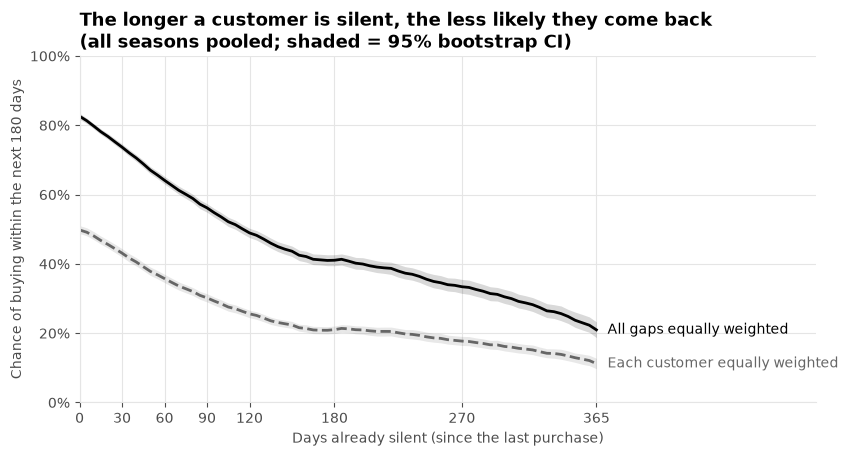

In [12]:
fig, ax = plt.subplots(figsize=(9.5, 4.5))
for (name, curve), style in zip(curves.items(), ["-", "--"]):
    color = INK if style == "-" else NEUTRAL
    ax.plot(SILENCE_GRID, curve, style, color=color)
    ax.fill_between(SILENCE_GRID, bands[name][0], bands[name][1], color=color, alpha=0.15, linewidth=0)
    ax.annotate(name, (SILENCE_GRID[-1], curve[-1]), xytext=(8, 0), textcoords="offset points", va="center",
                color=color)
ax.set_xlim(0, 520)
ax.set_xticks([0, 30, 60, 90, 120, 180, 270, 365])
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Days already silent (since the last purchase)")
ax.set_ylabel(f"Chance of buying within the next {WINDOW} days")
ax.set_title("The longer a customer is silent, the less likely they come back\n(all seasons pooled; shaded = 95% bootstrap CI)")
ax.grid(axis="x")
save_fig(fig, "03_return_after_silence")
plt.show()

The 180-day window smooths over the shape. A shorter, 30-day window shows when silences actually end. The table compares all gaps with a cleaner subset: gaps that start in April–August 2010, outside the peak and from clean cohorts' active months.

In [13]:
BANDS = np.arange(0, 480, 30)
clean_offpeak = intervals.filter(pl.col("start").is_between(date(2010, 4, 1), date(2010, 8, 31)))
hazard = pl.DataFrame({
    "silent_days": [f"{a}-{a + 29}" for a in BANDS],
    "all_gaps_pct": conditional_return(
        SurvfuncRight(intervals["duration"].to_numpy(), intervals["event"].to_numpy()), BANDS, 30) * 100,
    "gaps_starting_apr_aug_2010_pct": conditional_return(
        SurvfuncRight(clean_offpeak["duration"].to_numpy(), clean_offpeak["event"].to_numpy()), BANDS, 30) * 100,
}).with_columns(pl.exclude("silent_days").round(1))
print("Chance that a silence ends with a purchase in the next 30 days, by how long it has lasted:")
hazard

Chance that a silence ends with a purchase in the next 30 days, by how long it has lasted:


silent_days,all_gaps_pct,gaps_starting_apr_aug_2010_pct
str,f64,f64
"""0-29""",41.4,39.7
"""30-59""",33.6,34.0
"""60-89""",23.8,27.6
"""90-119""",19.8,21.9
"""120-149""",15.8,19.3
"""150-179""",13.3,15.7
"""180-209""",11.2,11.1
"""210-239""",9.4,6.3
"""240-269""",6.9,4.0


**Findings: return after silence**

- **Over a 180-day window, the chance of coming back falls with silence.** It roughly halves by about 180 days of silence, in both weightings. The two weightings differ in level but share the same shape, and neither is a churn rate.
- **The 30-day view shows the real shape.**
  - The chance that a silence ends falls to a low at around 8–10 months.
  - It rises a little around one year: some customers reorder yearly.
  - **After about 13–14 months it drops sharply, and returns become rare.**
- The long-silence estimates rest on gaps that started in 2009–10 (the only ones that can be that long), and they pool all seasons.
- **For `04`:**
  - A churn window of about 12–13 months would avoid labelling yearly reorderers as churned.
  - A shorter window leaves more history for the features, but mislabels some of them.

## Summary

- **New customers:** in their first year, between about one in ten and one in five are active in any given month.
- **Retention follows the calendar:** activity in November is more than twice January's, for every age of customer.
- **Customers acquired in the peak are less likely to place a second order within a year,** about 8–12 points fewer, measured on a single autumn season.
- **Returns cluster within the first months of silence, with a small second wave around one year.** After about 13–14 months of silence, customers rarely come back.
- **Methodology:**
  - The December 2009 cohort is the existing base.
  - The January–March 2010 cohorts are flagged as partly existing customers, so the comparisons use cohorts from April 2010.
  - December 2011 is excluded as a partial month.
  - The averages use a balanced panel of cohorts.
  - Time-to-event questions use Kaplan-Meier, so that customers who have not had time to return are not counted as lost.
  - The silence curves use a bootstrap over customers.
- **For `04`:**
  - Define churn as no purchase in a fixed window after a cutoff, as a stated business choice.
  - About 12–13 months is the window that the return pattern supports. A shorter window leaves more history for the features, at the cost of mislabelling yearly reorderers.
  - Use acquisition season and seasonal buying as candidate features.